# Phase 6: Energy Regime Definition

## Objective

Classify industrial energy consumption into three operating regimes:

- Normal: Usage_kWh < P75
- High: P75 <= Usage_kWh < P90
- Peak: Usage_kWh >= P90

The 75th and 90th percentile thresholds are calculated using the training period only.

The current operating regime will later determine which forecasting model is selected. Future actual energy consumption must never be used to assign the regime at forecast time.

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

DATA_DIR = Path("../Data/processed")

INPUT_PATH = DATA_DIR / "steel_industry_model_ready.csv"
OUTPUT_PATH = DATA_DIR / "steel_industry_regimes.csv" 
THRESHOLD_PATH = DATA_DIR / "phase6_regime_thresholds.json"

RANDOM_STATE = 42

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_PATH.resolve()}"
    )

print("Input:", INPUT_PATH.resolve())

Input: D:\Research Paper Codes\Data\processed\steel_industry_model_ready.csv


## 1. Load and Validate the Model-Ready Dataset

Load the Phase 4 dataset and verify chronological order, unique timestamps, and regular 15-minute intervals before recreating the Phase 5 split.

In [3]:
df = pd.read_csv(INPUT_PATH, parse_dates=["timestamp"])

df = (
    df.sort_values("timestamp")
      .reset_index(drop=True)
)

required_columns = [
    "timestamp",
    "Usage_kWh",
    "target_15min",
    "target_1hour"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

assert df["timestamp"].notna().all()
assert df["timestamp"].is_unique
assert df["timestamp"].is_monotonic_increasing

intervals = df["timestamp"].diff().dropna()

assert (
    intervals == pd.Timedelta(minutes=15)
).all(), "Irregular timestamp intervals found."

assert df["Usage_kWh"].notna().all()

print("Dataset shape:", df.shape)
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())
print("Dataset validation passed.")

Dataset shape: (34940, 28)
Start: 2018-01-02 00:00:00
End: 2018-12-31 22:45:00
Dataset validation passed.


## 2. Reproduce the Phase 5 Chronological Split

Use the same split as Phase 5:

- First 80% of observations for training.
- Purge four observations immediately before the test period.
- Final 20% for testing.

The percentile thresholds must be calculated only from the training observations.

In [4]:
split_index = int(len(df) * 0.80)
PURGE_GAP = 4

train_end = split_index - PURGE_GAP

if train_end <= 0:
    raise ValueError("Insufficient data for the requested split.")

train_df = df.iloc[:train_end].copy()
purged_df = df.iloc[train_end:split_index].copy()
test_df = df.iloc[split_index:].copy()

assert len(purged_df) == PURGE_GAP

assert (
    train_df["timestamp"].max()
    < test_df["timestamp"].min()
)

print("Total observations:", len(df))
print("Training observations:", len(train_df))
print("Purged observations:", len(purged_df))
print("Test observations:", len(test_df))

print("\nTraining period:")
print(train_df["timestamp"].min(), "to", train_df["timestamp"].max())

print("\nTest period:")
print(test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Total observations: 34940
Training observations: 27948
Purged observations: 4
Test observations: 6988

Training period:
2018-01-02 00:00:00 to 2018-10-20 02:45:00

Test period:
2018-10-20 04:00:00 to 2018-12-31 22:45:00


## 3. Calculate Training-Only Regime Thresholds

Calculate P75 and P90 from the training period only.

- Normal: energy consumption below P75.
- High: energy consumption greater than or equal to P75 but below P90.
- Peak: energy consumption greater than or equal to P90.

Do not calculate thresholds from the complete dataset, because this would allow test-period information to influence regime definitions.

In [5]:
p75 = float(train_df["Usage_kWh"].quantile(0.75))
p90 = float(train_df["Usage_kWh"].quantile(0.90))

if p75 >= p90:
    raise ValueError(
        "Invalid thresholds: P75 must be lower than P90."
    )

print(f"P75 threshold: {p75:.3f} kWh")
print(f"P90 threshold: {p90:.3f} kWh")

thresholds = {
    "method": "training-only empirical quantiles",
    "training_start": str(train_df["timestamp"].min()),
    "training_end": str(train_df["timestamp"].max()),
    "training_rows": int(len(train_df)),
    "purge_gap": PURGE_GAP,
    "test_start": str(test_df["timestamp"].min()),
    "p75_kwh": p75,
    "p90_kwh": p90,
    "regime_rules": {
        "Normal": f"Usage_kWh < {p75}",
        "High": f"{p75} <= Usage_kWh < {p90}",
        "Peak": f"Usage_kWh >= {p90}"
    }
}

with open(THRESHOLD_PATH, "w", encoding="utf-8") as file:
    json.dump(thresholds, file, indent=4)

print("Threshold configuration saved.")

P75 threshold: 51.340 kWh
P90 threshold: 81.049 kWh
Threshold configuration saved.


## 4. Assign Energy Regimes

Assign labels using current `Usage_kWh` and the training-derived thresholds.

The labels describe the observed operating state at time t. For forecasting, this state may select a model for predicting future consumption, provided the current reading is available at the forecast origin.

In [6]:
def assign_regime(usage):
    if pd.isna(usage):
        return np.nan
    elif usage < p75:
        return "Normal"
    elif usage < p90:
        return "High"
    else:
        return "Peak"


df["Energy_Regime"] = (
    df["Usage_kWh"].apply(assign_regime)
)

assert df["Energy_Regime"].notna().all()

print("Regime assignment completed.")

display(
    df[
        ["timestamp", "Usage_kWh", "Energy_Regime"]
    ].head(10)
)

Regime assignment completed.


,timestamp,Usage_kWh,Energy_Regime
0,2018-01-02 00:00:00,4.61,Normal
1,2018-01-02 00:15:00,3.20,Normal
2,2018-01-02 00:30:00,3.85,Normal
3,2018-01-02 00:45:00,3.28,Normal
4,2018-01-02 01:00:00,3.35,Normal
5,2018-01-02 01:15:00,3.89,Normal
6,2018-01-02 01:30:00,3.28,Normal
7,2018-01-02 01:45:00,3.46,Normal
8,2018-01-02 02:00:00,3.78,Normal
9,2018-01-02 02:15:00,3.31,Normal


## 5. Check Regime Distribution

Report the number and percentage of observations in each regime, separately for training and test periods.

The percentages may differ from exactly 75%, 15%, and 10% in the test period because thresholds are fixed from training data.

In [7]:
def regime_distribution(data, split_name):
    counts = (
        data["Energy_Regime"]
        .value_counts()
        .reindex(["Normal", "High", "Peak"], fill_value=0)
    )

    percentages = counts / len(data) * 100

    return pd.DataFrame({
        "Split": split_name,
        "Regime": counts.index,
        "Count": counts.values,
        "Percentage": percentages.values
    })


train_regimes = df.iloc[:train_end].copy()
test_regimes = df.iloc[split_index:].copy()

distribution = pd.concat(
    [
        regime_distribution(train_regimes, "Train"),
        regime_distribution(test_regimes, "Test")
    ],
    ignore_index=True
)

display(distribution.round(2))

,Split,Regime,Count,Percentage
0,Train,Normal,20950,74.96
1,Train,High,4203,15.04
2,Train,Peak,2795,10.00
3,Test,Normal,5248,75.10
4,Test,High,1295,18.53
5,Test,Peak,445,6.37


## 6. Visualize Regime Distribution

Compare the number of observations in each regime across training and test periods.

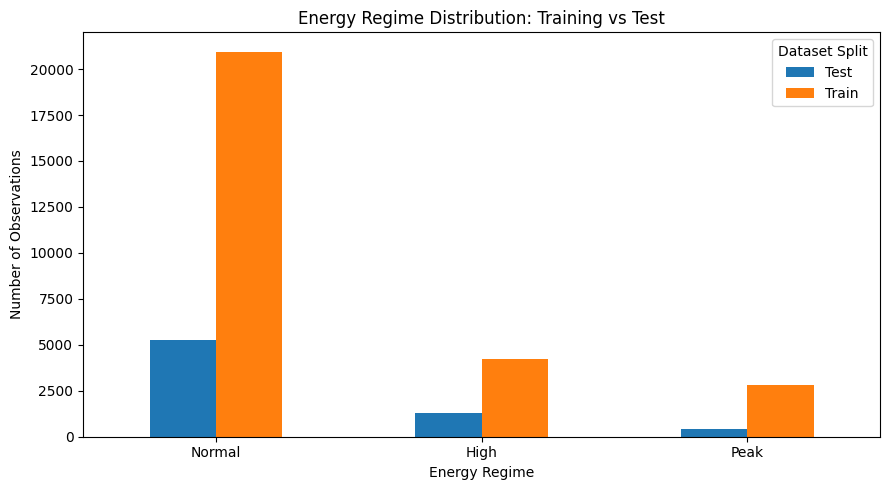

In [8]:
pivot_counts = distribution.pivot(
    index="Regime",
    columns="Split",
    values="Count"
).reindex(["Normal", "High", "Peak"])

ax = pivot_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Energy Regime Distribution: Training vs Test")
ax.set_xlabel("Energy Regime")
ax.set_ylabel("Number of Observations")
ax.legend(title="Dataset Split")
ax.tick_params(axis="x", rotation=0)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

## 7. Save the Regime-Labelled Dataset

Save the labelled dataset and threshold configuration for use in Phase 7.

The purged observations are retained in the labelled dataset but are not part of either the training or test set.

In [9]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_PATH, index=False)

print("Regime-labelled dataset saved to:")
print(OUTPUT_PATH.resolve())

print("\nThreshold file saved to:")
print(THRESHOLD_PATH.resolve())

print("\nFinal dataset shape:", df.shape)

Regime-labelled dataset saved to:
D:\Research Paper Codes\Data\processed\steel_industry_regimes.csv

Threshold file saved to:
D:\Research Paper Codes\Data\processed\phase6_regime_thresholds.json

Final dataset shape: (34940, 29)
